#  Apprentissage par renforcement (RL)

Ce notebook est prévu pour **Google Colab** (Exécution > Tout exécuter).

Particularité Colab : il n'y a pas d'écran, donc `render_mode="human"` (fenêtre pygame) ne fonctionne pas. On utilise `render_mode="rgb_array"` et on enregistre une vidéo affichée dans le notebook.

**Plan**
1. Installation
2. Découverte de Gymnasium (agent aléatoire)
3. Exemple 1 : PPO + test d'un épisode
4. Exemple 2 : PPO + 5 épisodes + courbe
5. Évaluation et courbe d'apprentissage
6. Effet du nombre de pas d'entraînement
7. Comparaison PPO / A2C / DQN
8. Ray RLlib
9. Coach et Dopamine (comparaison)
10. Réponse à la question et rapport

## 1. Installation

In [1]:
!pip install -q 'stable-baselines3[extra]' 'gymnasium[classic-control]' moviepy matplotlib seaborn pandas

In [2]:
import os, glob, base64, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium.wrappers import RecordVideo
from IPython.display import HTML, display

import stable_baselines3
from stable_baselines3 import PPO, A2C, DQN
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.evaluation import evaluate_policy

print('gymnasium', gym.__version__, '| SB3', stable_baselines3.__version__)

def show_video(folder):
    """Affiche dans le notebook toutes les vidéos .mp4 d'un dossier."""
    for f in sorted(glob.glob(os.path.join(folder, '*.mp4'))):
        b64 = base64.b64encode(open(f, 'rb').read()).decode()
        display(HTML(f'<p>{os.path.basename(f)}</p><video width=480 controls><source src="data:video/mp4;base64,{b64}" type="video/mp4"></video>'))

def record_episodes(model, folder, n_episodes=1):
    """Fait jouer le modèle et enregistre une vidéo par épisode. Retourne la liste des récompenses."""
    shutil.rmtree(folder, ignore_errors=True)
    env = gym.make('CartPole-v1', render_mode='rgb_array')
    env = RecordVideo(env, folder, episode_trigger=lambda ep: True)
    rewards = []
    for ep in range(n_episodes):
        obs, info = env.reset()
        done, total = False, 0.0
        while not done:
            action, _ = model.predict(obs, deterministic=True)
            obs, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated
            total += reward
        rewards.append(total)
        print(f'Épisode {ep+1} - Récompense : {total}')
    env.close()
    return rewards

gymnasium 1.4.0 | SB3 2.9.2


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 2. Découverte de Gymnasium : le MDP de CartPole

| Élément du MDP | CartPole |
|---|---|
| S (états) | position du chariot, vitesse du chariot, angle de la tige, vitesse angulaire |
| A (actions) | 0 = pousser à gauche, 1 = pousser à droite |
| R (récompense) | +1 à chaque pas où la tige reste droite |
| P (transition) | dynamique physique du système |
| gamma | facteur d'actualisation (0.99 par défaut dans PPO de SB3) |

In [3]:
env = gym.make('CartPole-v1')
print('Espace d observation :', env.observation_space)
print('Espace d actions     :', env.action_space)
print('Nombre max de pas    :', env.spec.max_episode_steps)

obs, info = env.reset(seed=0)
print('Observation initiale :', obs)

# Agent aléatoire : référence de comparaison
random_rewards = []
for ep in range(20):
    obs, info = env.reset()
    done, total = False, 0
    while not done:
        obs, r, terminated, truncated, info = env.step(env.action_space.sample())
        done = terminated or truncated
        total += r
    random_rewards.append(total)
env.close()
print(f'Agent aléatoire : récompense moyenne = {np.mean(random_rewards):.1f} +/- {np.std(random_rewards):.1f}')

Espace d observation : Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Espace d actions     : Discrete(2)
Nombre max de pas    : 500
Observation initiale : [ 0.01369617 -0.02302133 -0.04590265 -0.04834723]
Agent aléatoire : récompense moyenne = 19.4 +/- 9.6


**Interprétation :** un agent aléatoire tient environ 20 pas. C'est la ligne de base à battre.

## 3. Exemple 1 : PPO + test d'un épisode

On entraîne sur un environnement **sans rendu** (beaucoup plus rapide) et on enregistre seulement le test.

In [4]:
train_env = gym.make('CartPole-v1')
model1 = PPO('MlpPolicy', train_env, verbose=1, seed=42)

print('Entraînement en cours...')
model1.learn(total_timesteps=10000)
print('Entraînement terminé !')

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Entraînement en cours...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 22       |
|    ep_rew_mean     | 22       |
| time/              |          |
|    fps             | 1456     |
|    iterations      | 1        |
|    time_elapsed    | 1        |
|    total_timesteps | 2048     |
---------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 24.6        |
|    ep_rew_mean          | 24.6        |
| time/                   |             |
|    fps                  | 1065        |
|    iterations           | 2           |
|    time_elapsed         | 3           |
|    total_timesteps      | 4096        |
| train/                  |             |
|    approx_kl            | 0.008349767 |
|    clip_fraction        | 0.0965      |
|    clip_range           | 0.2         |
|    entropy_loss         | -0.686      |
|    explained_variance   | 0.00935     |
|    learning_rate        | 0.

In [5]:
r = record_episodes(model1, 'videos_ex1', n_episodes=1)
print(f'Récompense totale de l\'épisode : {r[0]}')
show_video('videos_ex1')

Épisode 1 - Récompense : 500.0


/usr/local/lib/python3.13/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"


Récompense totale de l'épisode : 500.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Explication de l'exemple 1**
- `PPO('MlpPolicy', env)` : algorithme acteur-critique avec un réseau de neurones (MLP). L'acteur apprend la politique, le critique estime la valeur V(s).
- Pendant `learn`, SB3 affiche des métriques par itération (2048 pas chacune) : `ep_len_mean` et `ep_rew_mean` doivent augmenter, `explained_variance` doit se rapprocher de 1, `clip_fraction` et `approx_kl` restent faibles grâce au clipping de PPO.
- Au test, `deterministic=True` : l'agent prend toujours l'action la plus probable, sans exploration.
- Récompense = durée de l'épisode. Maximum 500 (limite de troncature). 10 000 pas est un petit budget : le résultat est souvent partiel (50 à 200).

## 4. Exemple 2 : PPO + 5 épisodes de test + courbe

Épisode 1 - Récompense : 190.0
Épisode 2 - Récompense : 500.0
Épisode 3 - Récompense : 500.0
Épisode 4 - Récompense : 500.0
Épisode 5 - Récompense : 500.0


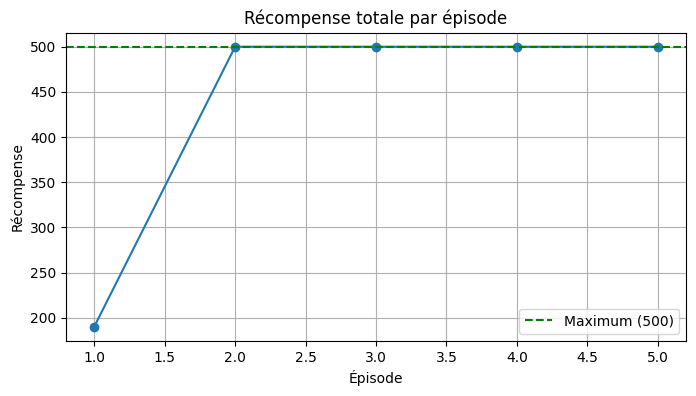

In [6]:
train_env2 = gym.make('CartPole-v1')
model2 = PPO('MlpPolicy', train_env2, verbose=0, seed=42)
model2.learn(total_timesteps=10000)

num_episodes = 5
rewards_list = record_episodes(model2, 'videos_ex2', n_episodes=num_episodes)

plt.figure(figsize=(8, 4))
plt.plot(range(1, num_episodes + 1), rewards_list, marker='o')
plt.axhline(500, color='green', linestyle='--', label='Maximum (500)')
plt.title('Récompense totale par épisode')
plt.xlabel('Épisode')
plt.ylabel('Récompense')
plt.legend()
plt.grid(True)
plt.show()

show_video('videos_ex2')

**Explication de l'exemple 2**
- On teste 5 épisodes au lieu d'un seul et on trace la récompense par épisode.
- La politique est déterministe : la variabilité vient seulement de l'état initial tiré au hasard à chaque `reset()`.
- Courbe plate proche de 500 : politique robuste. Courbe irrégulière : politique fragile, réussie seulement pour certains états de départ.
- Le modèle est un nouvel entraînement, indépendant de l'exemple 1.

## 5. Évaluation fiable et courbe d'apprentissage

`evaluate_policy` donne une moyenne et un écart-type sur beaucoup d'épisodes. Le wrapper `Monitor` enregistre les récompenses pendant l'entraînement.

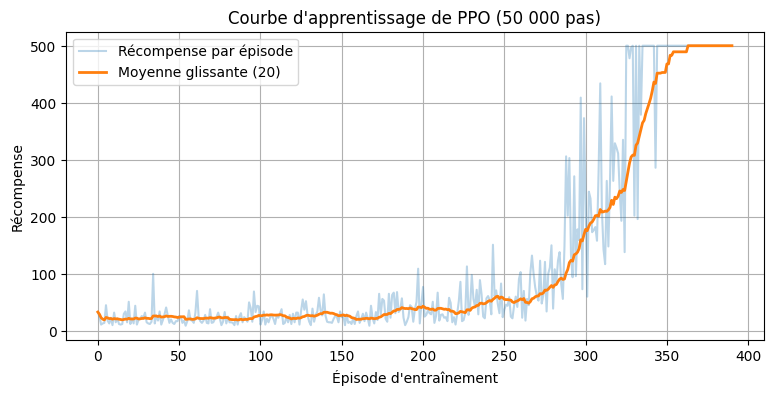

Évaluation sur 20 épisodes : 500.0 +/- 0.0


In [7]:
mon_env = Monitor(gym.make('CartPole-v1'))
model3 = PPO('MlpPolicy', mon_env, verbose=0, seed=42)
model3.learn(total_timesteps=50000)

# Courbe d'apprentissage (récompense par épisode d'entraînement)
ep_rewards = mon_env.get_episode_rewards()
window = 20
smooth = pd.Series(ep_rewards).rolling(window, min_periods=1).mean()

plt.figure(figsize=(9, 4))
plt.plot(ep_rewards, alpha=0.3, label='Récompense par épisode')
plt.plot(smooth, linewidth=2, label=f'Moyenne glissante ({window})')
plt.title('Courbe d\'apprentissage de PPO (50 000 pas)')
plt.xlabel('Épisode d\'entraînement')
plt.ylabel('Récompense')
plt.legend()
plt.grid(True)
plt.show()

eval_env = Monitor(gym.make('CartPole-v1'))
mean_r, std_r = evaluate_policy(model3, eval_env, n_eval_episodes=20, deterministic=True)
print(f'Évaluation sur 20 épisodes : {mean_r:.1f} +/- {std_r:.1f}')

In [8]:
r = record_episodes(model3, 'videos_ppo50k', n_episodes=1)
show_video('videos_ppo50k')

Épisode 1 - Récompense : 500.0


## 6. Effet du nombre de pas d'entraînement

   5000 pas -> 354.7 +/- 178.0
  10000 pas -> 413.6 +/- 104.4
  25000 pas -> 500.0 +/- 0.0
  50000 pas -> 500.0 +/- 0.0
 100000 pas -> 500.0 +/- 0.0


/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2010: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.space          = oneOf(self._space_widths)("space")
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2020: PyparsingDeprecationWarning: 'leaveWhitespace' deprecated - use 'leave_whitespace'
  )("sym").leaveWhitespace()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:1984: PyparsingDeprecationWarning: 'setName' deprecated - use 'set_name'
  val.setName(key)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:1987: PyparsingDeprecationWarning: 'setParseA

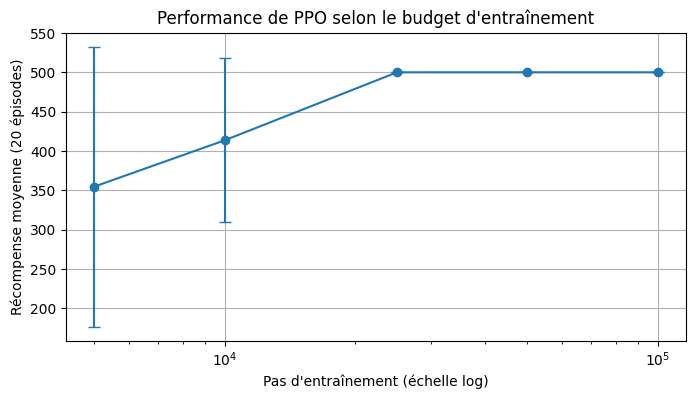

In [9]:
budgets = [5000, 10000, 25000, 50000, 100000]
results = []
for steps in budgets:
    m = PPO('MlpPolicy', gym.make('CartPole-v1'), verbose=0, seed=42)
    m.learn(total_timesteps=steps)
    mean_r, std_r = evaluate_policy(m, Monitor(gym.make('CartPole-v1')), n_eval_episodes=20)
    results.append((steps, mean_r, std_r))
    print(f'{steps:>7} pas -> {mean_r:.1f} +/- {std_r:.1f}')

df = pd.DataFrame(results, columns=['timesteps', 'mean', 'std'])
plt.figure(figsize=(8, 4))
plt.errorbar(df['timesteps'], df['mean'], yerr=df['std'], marker='o', capsize=4)
plt.xscale('log')
plt.title('Performance de PPO selon le budget d\'entraînement')
plt.xlabel('Pas d\'entraînement (échelle log)')
plt.ylabel('Récompense moyenne (20 épisodes)')
plt.grid(True)
plt.show()

**Conclusion :** la performance augmente avec le nombre de pas et finit par atteindre le maximum de 500. Cela confirme que 10 000 pas est insuffisant dans les exemples du TP.

## 7. Comparaison PPO / A2C / DQN

- PPO et A2C : acteur-critique (policy gradient).
- DQN : méthode à base de valeurs (Q-learning profond).

PPO: 500.0 +/- 0.0 (temps : 63 s)
A2C: 500.0 +/- 0.0 (temps : 73 s)
DQN: 159.5 +/- 42.8 (temps : 47 s)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Algorithme,Récompense moyenne,Écart-type,Temps (s)
0,PPO,500.0,0.000000,62.539975
1,A2C,500.0,0.000000,72.774574
2,DQN,159.5,42.756871,47.436433


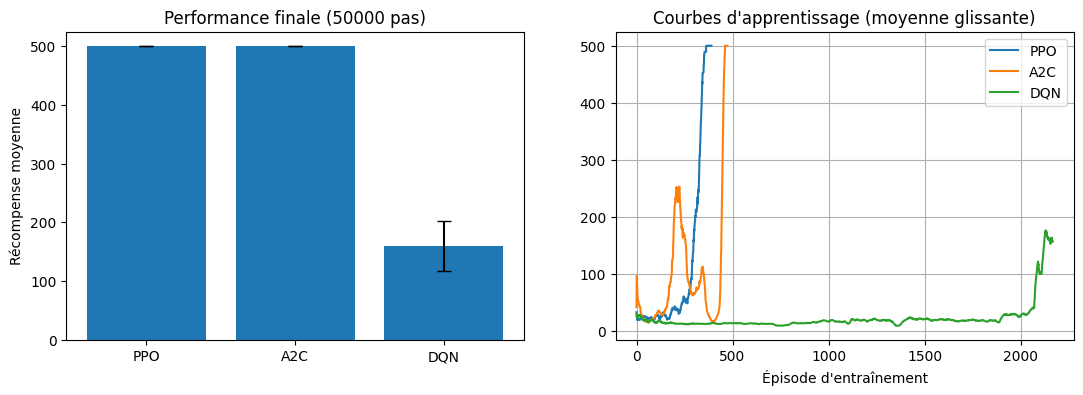

In [10]:
import time
algos = {'PPO': PPO, 'A2C': A2C, 'DQN': DQN}
steps = 50000
comp = []
curves = {}

for name, Algo in algos.items():
    menv = Monitor(gym.make('CartPole-v1'))
    m = Algo('MlpPolicy', menv, verbose=0, seed=42)
    t0 = time.time()
    m.learn(total_timesteps=steps)
    duration = time.time() - t0
    mean_r, std_r = evaluate_policy(m, Monitor(gym.make('CartPole-v1')), n_eval_episodes=20)
    comp.append((name, mean_r, std_r, duration))
    curves[name] = pd.Series(menv.get_episode_rewards()).rolling(20, min_periods=1).mean()
    print(f'{name}: {mean_r:.1f} +/- {std_r:.1f} (temps : {duration:.0f} s)')

df_comp = pd.DataFrame(comp, columns=['Algorithme', 'Récompense moyenne', 'Écart-type', 'Temps (s)'])
display(df_comp)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(df_comp['Algorithme'], df_comp['Récompense moyenne'], yerr=df_comp['Écart-type'], capsize=5)
ax[0].set_title(f'Performance finale ({steps} pas)')
ax[0].set_ylabel('Récompense moyenne')
for name, c in curves.items():
    ax[1].plot(c, label=name)
ax[1].set_title('Courbes d\'apprentissage (moyenne glissante)')
ax[1].set_xlabel('Épisode d\'entraînement')
ax[1].legend()
ax[1].grid(True)
plt.show()

**Analyse :** les résultats dépendent de la graine et des hyperparamètres par défaut. En général PPO est stable et rapide sur CartPole, A2C est plus bruyant, et DQN avec les hyperparamètres par défaut de SB3 peut être lent à converger sur ce budget. Un réglage (taux d'apprentissage, taille du buffer, exploration) améliore DQN.

## 8. Ray RLlib (entraînement distribué)

RLlib répartit la collecte d'expérience sur plusieurs workers. Sur Colab on dispose de peu de cœurs, donc l'objectif est de montrer la configuration. L'API de RLlib change souvent entre versions ; la cellule gère les deux principales.

In [ ]:
!pip install -q 'ray[rllib]'

In [ ]:
import ray
from ray.rllib.algorithms.ppo import PPOConfig

ray.shutdown()
ray.init(ignore_reinit_error=True, num_cpus=2, include_dashboard=False)

config = PPOConfig().environment('CartPole-v1').framework('torch')

# Nombre de workers : nom de méthode différent selon la version de Ray
try:
    config = config.env_runners(num_env_runners=1)
except AttributeError:
    config = config.rollouts(num_rollout_workers=1)

algo = config.build()

def get_reward(res):
    if 'env_runners' in res and 'episode_return_mean' in res['env_runners']:
        return res['env_runners']['episode_return_mean']
    return res.get('episode_reward_mean', float('nan'))

rllib_rewards = []
for i in range(10):
    res = algo.train()
    rllib_rewards.append(get_reward(res))
    print(f'Itération {i+1:2d} - récompense moyenne : {rllib_rewards[-1]:.1f}')

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(rllib_rewards) + 1), rllib_rewards, marker='o')
plt.title('RLlib PPO sur CartPole-v1')
plt.xlabel('Itération')
plt.ylabel('Récompense moyenne')
plt.grid(True)
plt.show()

algo.stop()
ray.shutdown()

**Remarque :** pour passer à l'échelle, on augmente `num_env_runners` (ou `num_rollout_workers`) et on utilise un cluster Ray avec plusieurs machines. C'est l'avantage principal de RLlib par rapport à SB3.

## 9. Coach et Dopamine : comparaison des frameworks

Ces deux bibliothèques sont peu maintenues et s'installent mal sur les versions récentes de Python (dépendances TensorFlow anciennes). Pour cette raison, on les compare ici sur le plan conceptuel plutôt que de les exécuter sur Colab.

| Critère | Stable-Baselines3 | Ray RLlib | Coach (Intel) | Dopamine (Google) |
|---|---|---|---|---|
| Backend | PyTorch | PyTorch / TensorFlow | TensorFlow | TensorFlow / JAX |
| Facilité d'usage | Très facile (API type scikit-learn) | Moyenne (configuration riche) | Moyenne (presets, fichiers de config) | Moyenne (fichiers gin) |
| Algorithmes | PPO, A2C, DQN, SAC, TD3, DDPG... | Très large (PPO, IMPALA, APEX, SAC, multi-agent...) | Large, orienté recherche | Peu : DQN, C51, Rainbow, IQN, SAC |
| Distribué | Limité (envs vectorisés) | Excellent (cluster Ray) | Possible (multi-workers) | Non natif |
| Environnements | Gymnasium | Gymnasium, multi-agent, externes | Gym, Atari, Doom... | Surtout Atari |
| Maintenance | Active | Active | Arrêtée | Faible |
| Usage idéal | Prototypage, enseignement, baselines | Production, grande échelle | Expériences de recherche historiques | Reproduire des résultats Atari |

**Conclusion :** SB3 pour apprendre et prototyper vite, RLlib pour passer à l'échelle, Coach et Dopamine surtout pour reproduire des travaux de recherche existants.

## 10. Réponse à la question du TP et rapport

### Question : expliquez les résultats des deux exemples

1. **Principe commun.** L'agent interagit avec CartPole, reçoit +1 par pas où la tige reste debout, et PPO ajuste sa politique pour allonger l'épisode. Le score maximal est 500.
2. **Exemple 1.** Après 10 000 pas, l'agent a commencé à apprendre : sa récompense dépasse largement celle de l'agent aléatoire (~20), mais est souvent loin de 500. Le test sur un seul épisode est peu informatif.
3. **Exemple 2.** Le test sur 5 épisodes montre la variabilité entre épisodes (états initiaux différents). Une courbe irrégulière indique une politique encore fragile.
4. **Limites.** Entraînement trop court, un seul entraînement, pas de graine fixée, rendu `human` qui ralentit tout.

### Améliorations proposées
- Augmenter `total_timesteps` à 50 000 ou plus (section 6).
- Fixer la graine (`seed=42`) pour la reproductibilité.
- Évaluer avec `evaluate_policy` sur 20 épisodes ou plus (section 5).
- Suivre la courbe d'apprentissage avec `Monitor` ou TensorBoard.
- Séparer l'environnement d'entraînement (sans rendu) de celui de test (avec rendu).
- Régler les hyperparamètres (`learning_rate`, `n_steps`, `gamma`, `ent_coef`).
- Comparer plusieurs algorithmes (section 7).

### Trame du rapport à rendre
1. Introduction : définition du RL, MDP, rôle de la fonction de récompense.
2. Méthodes : environnement CartPole, algorithmes (PPO, A2C, DQN), outils (Gymnasium, SB3, RLlib).
3. Résultats : agent aléatoire, courbes des sections 4 à 7, tableau comparatif.
4. Discussion : interprétation des courbes, limites, comparaison des frameworks.
5. Conclusion et pistes d'amélioration.

*Astuce : copiez vos vraies valeurs et captures de courbes dans le rapport, elles varient d'une exécution à l'autre.*